# 01 — Global grayscale features: cone / sign

One object, one feature vector. Mask-only reference and original full-crop input. No sliding windows.

## Twelve feature methods and fixed definitions

All images are converted to 8-bit grayscale **before** extraction. Let S be selected pixels, N=|S|, p(r)=count(r)/N, r=0,...,255. `mask` uses only S={mask>0}; `crop` uses the entire rectangular crop, including its original background. Mask-outside pixels are never replaced by black pixels and included in the average.

| Method | Formula / definition | Origin |
|---|---|---|
| Histogram | p(r), 256 normalized bins | Slides |
| Mean | μ=Σ r p(r) | Slides, explicit formula |
| Median | median of selected intensities | Slides, text |
| Mode | argmax p(r); lowest intensity on ties | Slides, text |
| Variance | σ²=Σ(r−μ)²p(r), population variance | Slides, explicit formula |
| Std / RMS contrast | σ=√variance | Slides mention std/contrast; RMS definition chosen here |
| Trimmed mean | sort intensities, drop floor(0.1N) from each tail, average remainder | Slides' alpha-trimmed mean; 10% fixed here |
| Entropy | H=−Σ p(r)log₂p(r), omit zero bins | Slides mention entropy; formula supplied here |
| Gray-range fraction | Σ p(r) for 64≤r≤192 | Slides mention area within a gray range; normalized range fixed here |
| Entropy × Contrast | Hσ | Additional engineered feature, not from slides |
| Normalized contrast | σ/(μ+1) | Additional engineered feature, not from slides |
| Spatial entropy difference | abs(H(top)−H(bottom)), split at floor(crop height/2), retain 2D mask positions | Additional spatial feature, not from slides |

The histogram is a vector, not a scalar statistic. Spatial entropy is not purely a global histogram statistic. If either half has no selected pixels, spatial entropy is undefined (NaN), reported and excluded for that feature. Entropy uses the same 256 gray levels everywhere. No local windows, NMS, or bounding-box matching.

## Evaluation protocol

Reference/calibration use only `role=template`, split by source image with seed 42. `role=validation` is held out. All three source sets are disjoint. Clean mask-only class centroids are fitted using reference sources, with equal weight per source within each class. No mask-complement samples are used as a classification class.

Each of the 12 features is evaluated as **cone versus sign**, with separate one-versus-other-class decisions for cone and sign. Scalar distance is absolute difference; histogram distance is Σ(a−b)²/max(a,b), with zero/zero contributing zero. Margin = distance to other class − distance to own class. Accept a class when margin ≥ its calibrated threshold. A score is not a probability. Independent class decisions may both accept or both reject a crop.

Thresholds and the best feature for each class are selected **only on full, background-containing calibration crops**, using source-balanced accuracy=(source-weighted sensitivity+specificity)/2. Exact feature ties use declared feature order. Frozen references, thresholds and winners are then evaluated on held-out masks and held-out full crops. The same threshold is used for both input views. Precision/recall/F1 use raw crop counts and are additionally reported.

Masks give exact computation regions relative to the supplied annotation, not perfect semantic labels or guaranteed 100% recognition. Masks are eroded. Full-crop background is the original surrounding content already inside each crop; it does not simulate arbitrary scene backgrounds. Negatives are the opposite object class, not pure-background scenes. These results are supplied-ROI class recognition, not object detection. Do not select a new winner after seeing held-out results.

## Setup and reusable analysis functions

Dependencies: numpy, pandas, pillow, matplotlib. Local path discovery is included; in Colab mount Drive first and adjust PROJECT if needed.

In [1]:
from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
from IPython.display import display

LOCAL = Path('/Users/yingying/Downloads/midterm-csc74030-main')
COLAB = Path('/content/drive/MyDrive/ComputerVision/Midterm/midterm-csc74030-main')
PROJECT = next((p for p in [Path.cwd(), *Path.cwd().parents, LOCAL, COLAB]
                if (p/'vistas_templates/templates.csv').is_file()), None)
if PROJECT is None:
    raise FileNotFoundError('Set PROJECT to the folder containing vistas_templates.')
DATA = PROJECT/'vistas_templates'
RESULTS = PROJECT/'intensity_results/vistas_global'
CLASSES = ('cone', 'sign')
FEATURES = (
    'Histogram', 'Mean', 'Median', 'Mode', 'Variance',
    'Std / RMS contrast', 'Trimmed mean', 'Entropy', 'Gray-range fraction',
    'Entropy × Contrast', 'Normalized contrast', 'Spatial entropy difference',
)
VIEWS = ('mask', 'crop')
SEED = 42
VERSION = 'global-mask-crop-v1'


def read_manifest():
    """Validate crop identity and source separation before extracting features."""
    table = pd.read_csv(DATA/'templates.csv')
    required = {'crop', 'mask', 'class', 'role', 'source_key'}
    if not required.issubset(table.columns):
        raise ValueError(f'Missing columns: {required-set(table.columns)}')
    if table.crop.duplicated().any():
        raise ValueError('Duplicate crop paths.')
    if not table['class'].isin(CLASSES).all():
        raise ValueError('Only cone and sign are supported.')
    if not table.role.isin(['template', 'validation']).all():
        raise ValueError('Unexpected data role.')
    role_sources = table.groupby('source_key').role.nunique()
    if (role_sources > 1).any():
        raise ValueError('A source image occurs in both template and validation roles.')
    return table


def split_sources(table):
    """Use only template-role sources for reference fitting and calibration."""
    rng = np.random.default_rng(SEED)
    calibration_sources = set()
    for cls in CLASSES:
        sources = np.array(sorted(table.loc[
            (table.role == 'template') & (table['class'] == cls), 'source_key'].unique()))
        if len(sources) < 2:
            raise ValueError(f'Not enough template sources for {cls}.')
        rng.shuffle(sources)
        calibration_sources.update(sources[:max(1, int(len(sources)*.25))])
    table = table.copy()
    table['usage'] = np.where(
        table.role == 'validation', 'held_out',
        np.where(table.source_key.isin(calibration_sources), 'calibration', 'reference'))
    if (table.groupby('source_key').usage.nunique() != 1).any():
        raise ValueError('Source leakage between splits.')
    for usage in ('reference', 'calibration', 'held_out'):
        for cls in CLASSES:
            if not ((table.usage == usage) & (table['class'] == cls)).any():
                raise ValueError(f'Empty split: {usage}/{cls}.')
    return table


def load_crop(row):
    """Convert RGB to 8-bit grayscale BEFORE applying the object mask."""
    with Image.open(DATA/row['crop']) as image:
        gray = np.array(image.convert('L'))
    with Image.open(DATA/row['mask']) as image:
        mask = np.array(image.convert('L')) > 0
    if gray.shape != mask.shape or not mask.any():
        raise ValueError(f"Invalid mask: {row['crop']}")
    return gray, mask


def histogram(pixels):
    counts = np.bincount(np.asarray(pixels).ravel(), minlength=256)
    if counts.sum() == 0:
        raise ValueError('Cannot describe an empty region.')
    return counts.astype(float)/counts.sum()


def entropy(pixels):
    p = histogram(pixels)
    nonzero = p[p > 0]
    return float(-(nonzero*np.log2(nonzero)).sum())


def extract_features(gray, region):
    """One vector per object: mask pixels or all crop pixels; no windows."""
    pixels = gray[region]
    if not pixels.size:
        raise ValueError('Empty computation region.')
    p = histogram(pixels)
    values = pixels.astype(float)
    mean = float(values.mean())
    variance = float(values.var())  # population variance, ddof=0
    std = float(np.sqrt(variance))
    ordered = np.sort(values)
    cut = int(np.floor(.10*len(ordered)))
    trimmed = ordered[cut:len(ordered)-cut] if cut else ordered
    h = entropy(pixels)
    middle = gray.shape[0]//2
    top = gray[:middle][region[:middle]]
    bottom = gray[middle:][region[middle:]]
    # Spatial entropy is undefined when either half contains no selected pixels.
    spatial = abs(entropy(top)-entropy(bottom)) if top.size and bottom.size else np.nan
    return {
        'Histogram': p,
        'Mean': mean,
        'Median': float(np.median(values)),
        'Mode': float(np.argmax(p)),  # lowest gray value wins an exact tie
        'Variance': variance,
        'Std / RMS contrast': std,
        'Trimmed mean': float(trimmed.mean()),
        'Entropy': h,
        'Gray-range fraction': float(p[64:193].sum()),  # inclusive [64, 192]
        'Entropy × Contrast': h*std,
        'Normalized contrast': std/(mean+1.),
        'Spatial entropy difference': spatial,
    }


def input_fingerprint(table):
    """Invalidate results if the manifest, crop/mask contents or code change."""
    digest = hashlib.sha256(VERSION.encode())
    digest.update((DATA/'templates.csv').read_bytes())
    for _, row in table.sort_values('crop').iterrows():
        for column in ('crop', 'mask'):
            digest.update(row[column].encode())
            digest.update((DATA/row[column]).read_bytes())
    return digest.hexdigest()


def build_feature_table(table):
    rows = []
    for _, row in table.iterrows():
        gray, mask = load_crop(row)
        base = {k: row[k] for k in ('crop', 'class', 'source_key', 'role', 'usage')}
        base.update(width=gray.shape[1], height=gray.shape[0],
                    object_pixels=int(mask.sum()),
                    background_fraction=float(1-mask.mean()))
        for view, region in [('mask', mask), ('crop', np.ones_like(mask))]:
            values = extract_features(gray, region)
            for feature in FEATURES:
                vector = np.atleast_1d(values[feature]).astype(float)
                rows.append(dict(base, view=view, feature=feature,
                                 valid=bool(np.isfinite(vector).all()),
                                 value=json.dumps(vector.tolist())))
    return pd.DataFrame(rows)


def matrix(rows):
    return np.array([json.loads(value) for value in rows.value], dtype=float)


def source_weights(rows):
    """Equal total weight per source image within each true class."""
    counts = rows.groupby(['class', 'source_key']).crop.transform('size')
    return 1./counts.to_numpy(dtype=float)


def fit_references(features):
    """Always fit clean, mask-only references; background is never a template."""
    model = {}
    for feature in FEATURES:
        subset = features[(features.usage == 'reference') &
                          (features.view == 'mask') & (features.feature == feature) & features.valid]
        model[feature] = {}
        for cls in CLASSES:
            rows = subset[subset['class'] == cls]
            if rows.empty:
                raise ValueError(f'No valid reference for {cls}/{feature}.')
            vector = np.average(matrix(rows), axis=0, weights=source_weights(rows))
            model[feature][cls] = vector.tolist()
    return model


def class_margin(rows, model, feature, cls):
    """Positive = closer to this class; references are fitted on clean objects."""
    values = matrix(rows)
    other = next(c for c in CLASSES if c != cls)
    own = np.array(model[feature][cls])
    opposite = np.array(model[feature][other])
    def distance(reference):
        if feature == 'Histogram':
            # Slide's max-denominator histogram distance; 0/0 contributes zero.
            return ((values-reference)**2/np.maximum(np.maximum(values, reference), 1e-30)).sum(1)
        return np.abs(values-reference).sum(1)
    return distance(opposite)-distance(own)


def classification_metrics(rows, scores, cls, threshold):
    truth = rows['class'].to_numpy() == cls
    predicted = scores >= threshold
    weights = source_weights(rows)
    positive = weights[truth].sum()
    negative = weights[~truth].sum()
    tpr = float(weights[truth & predicted].sum()/positive) if positive else np.nan
    tnr = float(weights[~truth & ~predicted].sum()/negative) if negative else np.nan
    tp = int(np.sum(truth & predicted)); fp = int(np.sum(~truth & predicted))
    fn = int(np.sum(truth & ~predicted)); tn = int(np.sum(~truth & ~predicted))
    precision = tp/(tp+fp) if tp+fp else 0.
    recall = tp/(tp+fn) if tp+fn else 0.
    f1 = 2*precision*recall/(precision+recall) if precision+recall else 0.
    return dict(balanced_accuracy=(tpr+tnr)/2, source_weighted_tpr=tpr,
                source_weighted_tnr=tnr, precision=precision, recall=recall, f1=f1,
                tp=tp, fp=fp, fn=fn, tn=tn, evaluated=len(rows))


def threshold_candidates(scores):
    values = np.unique(scores)
    midpoints = values[:-1]+(values[1:]-values[:-1])/2
    return np.r_[np.nextafter(values[0], -np.inf), midpoints,
                 np.nextafter(values[-1], np.inf), 0.]


def evaluate_methods(features, model):
    """Freeze thresholds and winners on background-containing calibration crops."""
    thresholds = {}; curves = []; report = []
    for cls in CLASSES:
        thresholds[cls] = {}
        for feature in FEATURES:
            cal = features[(features.usage == 'calibration') & (features.view == 'crop') &
                           (features.feature == feature) & features.valid]
            scores = class_margin(cal, model, feature, cls)
            candidates = []
            for threshold in threshold_candidates(scores):
                result = classification_metrics(cal, scores, cls, float(threshold))
                item = dict(cls=cls, feature=feature, threshold=float(threshold), **result)
                candidates.append(item); curves.append(item)
            # Fixed tie rule; never consult held-out data when choosing a threshold.
            best = max(candidates, key=lambda r: (r['balanced_accuracy'], -abs(r['threshold']), -r['threshold']))
            thresholds[cls][feature] = best['threshold']
            for usage in ('calibration', 'held_out'):
                for view in VIEWS:
                    all_rows = features[(features.usage == usage) & (features.view == view) &
                                        (features.feature == feature)]
                    rows = all_rows[all_rows.valid]
                    result = classification_metrics(rows, class_margin(rows, model, feature, cls),
                                                    cls, best['threshold'])
                    report.append(dict(cls=cls, feature=feature, usage=usage, view=view,
                                       threshold=best['threshold'], excluded=len(all_rows)-len(rows), **result))
    report = pd.DataFrame(report)
    winners = {}
    for cls in CLASSES:
        cal = report[(report.cls == cls) & (report.usage == 'calibration') & (report.view == 'crop')]
        # Stable order in FEATURES resolves equal calibration scores.
        best = cal.sort_values('balanced_accuracy', ascending=False, kind='stable').iloc[0]
        winners[cls] = dict(feature=best.feature, threshold=float(best.threshold),
                            calibration_balanced_accuracy=float(best.balanced_accuracy))
    return report, thresholds, winners, pd.DataFrame(curves)


def descriptive_table(features):
    """All 11 scalars; each of the 256 histogram bins is exported separately."""
    rows = features[(features.feature != 'Histogram') & features.valid].copy()
    rows['statistic'] = rows.value.map(lambda s: json.loads(s)[0])
    return rows.groupby(['class', 'usage', 'view', 'feature']).statistic.agg(
        ['count', 'mean', 'std', 'min', 'median', 'max']).reset_index()


def run_analysis(force=False):
    table = split_sources(read_manifest())
    fingerprint = input_fingerprint(table)
    metadata_path = RESULTS/'run.json'
    if metadata_path.is_file() and not force:
        metadata = json.loads(metadata_path.read_text())
        if metadata.get('fingerprint') == fingerprint:
            return metadata
    RESULTS.mkdir(parents=True, exist_ok=True)
    features = build_feature_table(table)
    model = fit_references(features)
    report, thresholds, winners, curves = evaluate_methods(features, model)
    table.to_csv(RESULTS/'split_manifest.csv', index=False)
    features.to_csv(RESULTS/'object_features.csv', index=False)
    descriptive_table(features).to_csv(RESULTS/'statistics_summary.csv', index=False)
    report.to_csv(RESULTS/'all_method_scores.csv', index=False)
    curves.to_csv(RESULTS/'calibration_thresholds.csv', index=False)
    (RESULTS/'model.json').write_text(json.dumps(dict(references=model, thresholds=thresholds), indent=2))
    (RESULTS/'winners.json').write_text(json.dumps(winners, indent=2))
    for cls in CLASSES:
        folder = RESULTS/cls
        folder.mkdir(exist_ok=True)
        features[features['class'] == cls].to_csv(folder/'object_features.csv', index=False)
        report[report.cls == cls].to_csv(folder/'method_scores.csv', index=False)
        hist = features[(features['class'] == cls) & (features.feature == 'Histogram')]
        bins = pd.DataFrame(matrix(hist), columns=[f'gray_{i}' for i in range(256)])
        pd.concat([hist[['crop', 'source_key', 'usage', 'view']].reset_index(drop=True), bins], axis=1).to_csv(
            folder/'histograms.csv', index=False)
    metadata = dict(version=VERSION, fingerprint=fingerprint, winners=winners,
                    splits=table.groupby(['usage', 'class']).size().rename('count').reset_index().to_dict('records'),
                    selection='Highest source-balanced accuracy on complete-crop calibration data; ties use declared feature order.',
                    target='Per-class recognition of supplied cone/sign object crops, not background rejection or localization.')
    metadata_path.write_text(json.dumps(metadata, indent=2))
    return metadata


def load_results():
    metadata = run_analysis()
    features = pd.read_csv(RESULTS/'object_features.csv')
    scores = pd.read_csv(RESULTS/'all_method_scores.csv')
    descriptive = pd.read_csv(RESULTS/'statistics_summary.csv')
    return metadata, features, scores, descriptive


def show_scores(scores, cls):
    rows = scores[(scores.cls == cls) & (scores.usage == 'held_out')]
    table = rows.pivot(index='feature', columns='view', values='balanced_accuracy').reindex(FEATURES)
    table['crop_minus_mask'] = table['crop']-table['mask']
    display(table.round(4))
    table[['mask', 'crop']].plot.barh(figsize=(10, 7), xlim=(0, 1), title=f'{cls}: held-out class recognition')
    plt.axvline(.5, color='gray', linestyle='--')
    plt.xlabel('Source-balanced accuracy'); plt.tight_layout(); plt.show()


def predict_crop(image_path, cls):
    """Inference needs an object ROI only: no mask, annotations or window search."""
    if cls not in CLASSES:
        raise ValueError('cls must be cone or sign.')
    if not (RESULTS/'model.json').is_file() or not (RESULTS/'winners.json').is_file():
        raise FileNotFoundError('Run the analysis once before using the frozen classifier.')
    metadata = {'winners': json.loads((RESULTS/'winners.json').read_text())}
    model = json.loads((RESULTS/'model.json').read_text())
    selected = metadata['winners'][cls]
    with Image.open(image_path) as image:
        gray = np.array(image.convert('L'))
    feature = selected['feature']
    vector = np.atleast_1d(extract_features(gray, np.ones_like(gray, dtype=bool))[feature])
    if not np.isfinite(vector).all():
        raise ValueError('Selected feature is undefined for this crop.')
    row = pd.DataFrame([dict(value=json.dumps(vector.tolist()))])
    margin = float(class_margin(row, model['references'], feature, cls)[0])
    return dict(cls=cls, feature=feature, margin=margin, threshold=selected['threshold'],
                accepted=bool(margin >= selected['threshold']))

In [2]:
metadata, features, scores, descriptive = load_results()
display(pd.DataFrame(metadata['splits']))
print(metadata['target'])

,usage,class,count
0,calibration,cone,60
1,calibration,sign,11
2,held_out,cone,77
3,held_out,sign,35
4,reference,cone,183
5,reference,sign,36


Per-class recognition of supplied cone/sign object crops, not background rejection or localization.


## cone — numeric answers for all scalar methods

,class,usage,view,feature,count,mean,std,min,median,max
22,cone,held_out,crop,Entropy,77,7.0522,0.4540,5.3510,7.1090,7.7795
23,cone,held_out,crop,Entropy × Contrast,77,328.9970,105.4146,83.7031,311.8305,568.9894
24,cone,held_out,crop,Gray-range fraction,77,0.7027,0.1731,0.3134,0.7404,0.9875
25,cone,held_out,crop,Mean,77,120.8490,32.4729,57.7359,118.4838,199.0064
26,cone,held_out,crop,Median,77,117.1169,35.0264,30.0000,117.0000,202.0000
27,cone,held_out,crop,Mode,77,112.6623,68.8751,0.0000,109.0000,255.0000
28,cone,held_out,crop,Normalized contrast,77,0.4046,0.1638,0.1561,0.3736,0.9343
29,cone,held_out,crop,Spatial entropy difference,77,0.4076,0.3944,0.0139,0.2708,2.3316
30,cone,held_out,crop,Std / RMS contrast,77,45.9884,12.7360,14.8543,44.9175,75.9000
31,cone,held_out,crop,Trimmed mean,77,118.8522,33.9372,52.7904,116.4592,201.8326


Every object value is saved in cone/object_features.csv; all 256 histogram bins in cone/histograms.csv.


view,crop,mask,crop_minus_mask
feature,,,
Histogram,0.5764,0.5917,-0.0153
Mean,0.6080,0.6088,-0.0008
Median,0.5509,0.5491,0.0018
Mode,0.4990,0.5860,-0.0870
Variance,0.5911,0.6259,-0.0347
Std / RMS contrast,0.6218,0.6701,-0.0483
Trimmed mean,0.6458,0.6065,0.0393
Entropy,0.6149,0.6638,-0.0489
Gray-range fraction,0.5674,0.5553,0.0122


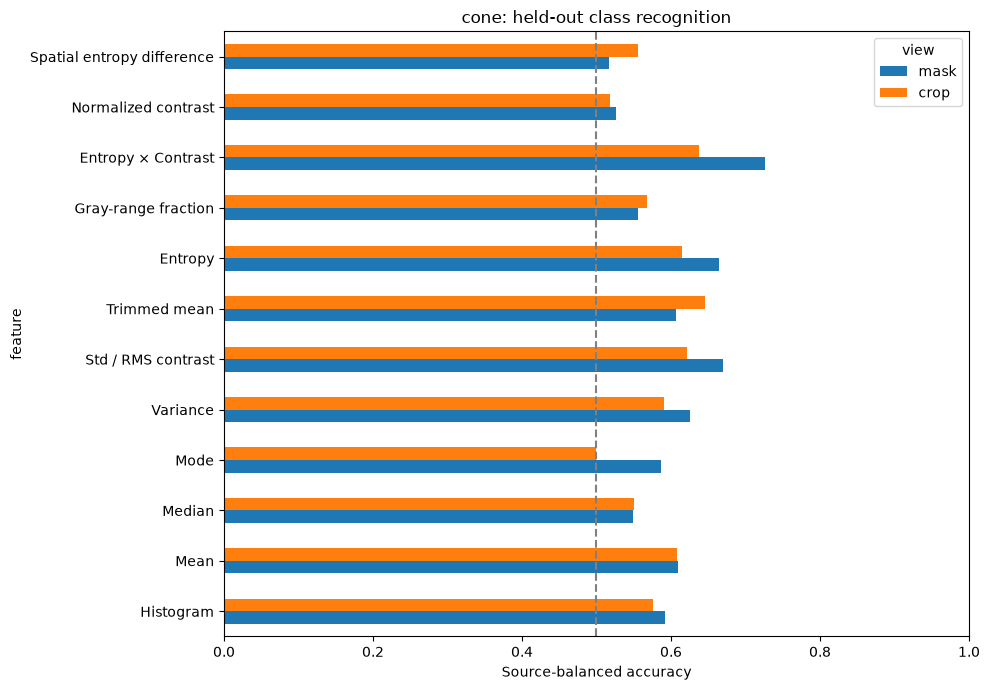

In [3]:
cls='cone'
rows=descriptive[(descriptive['class']==cls)&(descriptive.usage=='held_out')]
display(rows.round(4))
print('Every object value is saved in cone/object_features.csv; all 256 histogram bins in cone/histograms.csv.')
show_scores(scores,cls)

## cone — normalized grayscale histograms

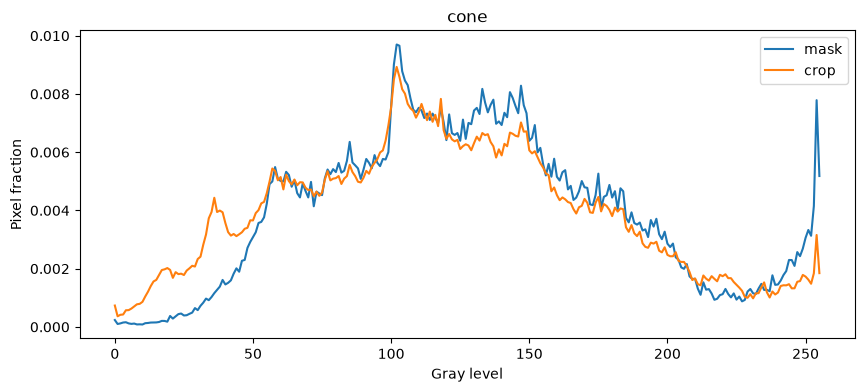

In [4]:
cls='cone'
fig,ax=plt.subplots(figsize=(10,4))
for view in VIEWS:
    rows=features[(features['class']==cls)&(features.usage=='held_out')&(features.view==view)&(features.feature=='Histogram')]
    mean=np.average(matrix(rows),axis=0,weights=source_weights(rows))
    ax.plot(np.arange(256),mean,label=view)
ax.set(xlabel='Gray level',ylabel='Pixel fraction',title=cls);ax.legend();plt.show()

## sign — numeric answers for all scalar methods

,class,usage,view,feature,count,mean,std,min,median,max
88,sign,held_out,crop,Entropy,35,6.7469,0.5255,5.7612,6.6676,7.7100
89,sign,held_out,crop,Entropy × Contrast,35,271.7924,114.1841,104.5903,265.1812,528.0547
90,sign,held_out,crop,Gray-range fraction,35,0.7243,0.1642,0.4650,0.7019,0.9994
91,sign,held_out,crop,Mean,35,103.9931,26.7277,57.2094,99.1080,169.5020
92,sign,held_out,crop,Median,35,106.8143,33.0156,59.0000,104.0000,185.0000
93,sign,held_out,crop,Mode,35,120.8000,48.7670,12.0000,113.0000,254.0000
94,sign,held_out,crop,Normalized contrast,35,0.3870,0.1356,0.1821,0.3858,0.7013
95,sign,held_out,crop,Spatial entropy difference,35,0.2729,0.2356,0.0060,0.2150,0.9353
96,sign,held_out,crop,Std / RMS contrast,35,39.4035,13.9004,17.9836,39.0805,70.8286
97,sign,held_out,crop,Trimmed mean,35,103.7279,28.6564,57.1926,99.1451,173.7439


Every object value is saved in sign/object_features.csv; all 256 histogram bins in sign/histograms.csv.


view,crop,mask,crop_minus_mask
feature,,,
Histogram,0.5764,0.5917,-0.0153
Mean,0.6080,0.6088,-0.0008
Median,0.5509,0.5491,0.0018
Mode,0.4990,0.5860,-0.0870
Variance,0.5911,0.6259,-0.0347
Std / RMS contrast,0.6218,0.6701,-0.0483
Trimmed mean,0.6458,0.6065,0.0393
Entropy,0.6149,0.6638,-0.0489
Gray-range fraction,0.5674,0.5553,0.0122


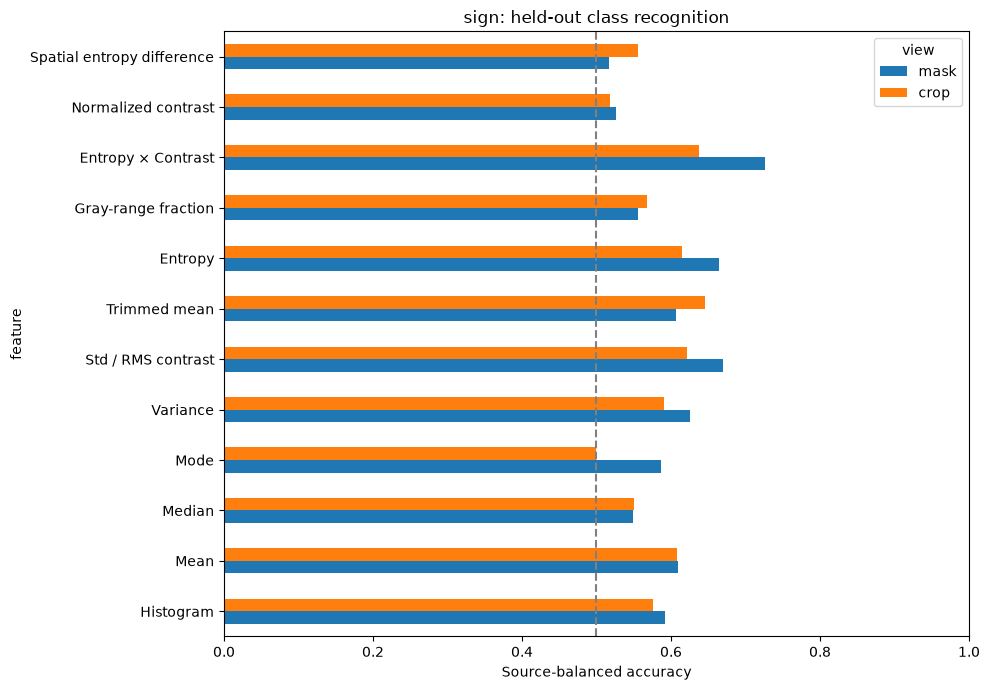

In [5]:
cls='sign'
rows=descriptive[(descriptive['class']==cls)&(descriptive.usage=='held_out')]
display(rows.round(4))
print('Every object value is saved in sign/object_features.csv; all 256 histogram bins in sign/histograms.csv.')
show_scores(scores,cls)

## sign — normalized grayscale histograms

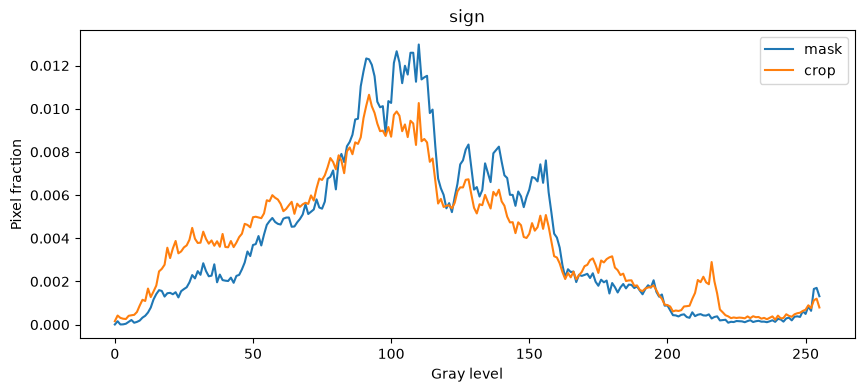

In [6]:
cls='sign'
fig,ax=plt.subplots(figsize=(10,4))
for view in VIEWS:
    rows=features[(features['class']==cls)&(features.usage=='held_out')&(features.view==view)&(features.feature=='Histogram')]
    mean=np.average(matrix(rows),axis=0,weights=source_weights(rows))
    ax.plot(np.arange(256),mean,label=view)
ax.set(xlabel='Gray level',ylabel='Pixel fraction',title=cls);ax.legend();plt.show()

## Inspect exact computation regions

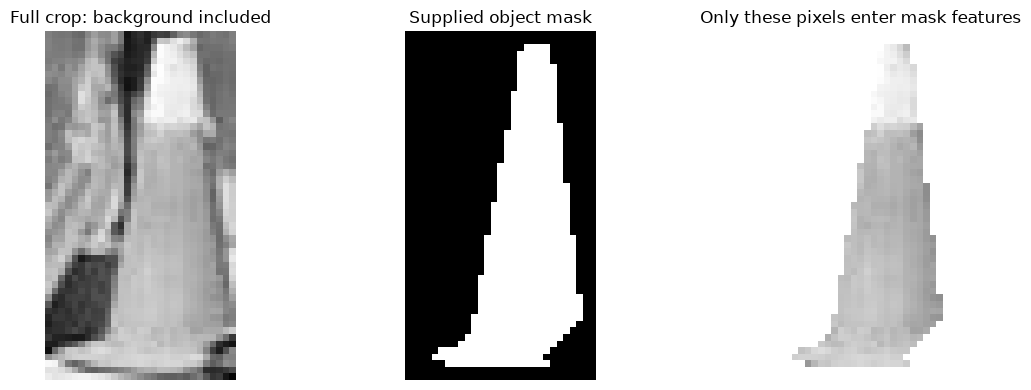

Mask-excluded fraction: 0.6396


In [7]:
CLASS='cone'
INDEX=0
row=split_sources(read_manifest()).query("usage=='held_out'")
row=row[row['class']==CLASS].iloc[INDEX]
gray,mask=load_crop(row)
fig,axes=plt.subplots(1,3,figsize=(12,4))
axes[0].imshow(gray,cmap='gray',vmin=0,vmax=255);axes[0].set_title('Full crop: background included')
axes[1].imshow(mask,cmap='gray');axes[1].set_title('Supplied object mask')
axes[2].imshow(np.ma.masked_where(~mask,gray),cmap='gray',vmin=0,vmax=255);axes[2].set_title('Only these pixels enter mask features')
for ax in axes:ax.axis('off')
plt.tight_layout();plt.show()
print('Mask-excluded fraction:',round(1-mask.mean(),4))